# COMP 472 · k-Nearest Neighbours
**Kaggle Project · Fall 2026**  
*Visual object recognition + sentiment analysis*

---

This notebook implements **k-NN from scratch with NumPy**, compares its performance across the two datasets, explores preprocessing and voting choices, and creates a Kaggle-ready submission.

**Workflow:** Load data → Train / validation split → k-NN → Hyperparameter experiments → Comparison → Submission

## 01 · Environment & datasets

Place all five Kaggle CSV files in the same directory as this notebook. Run the optional install cell only if a dependency is missing.

In [1]:
%pip install -q pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Rafay\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

image_train = pd.read_csv("image_train.csv")
image_test = pd.read_csv("image_test.csv")
sentiment_train = pd.read_csv("sentiment_train.csv")
sentiment_test = pd.read_csv("sentiment_test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

file_summary = pd.DataFrame({
    "Dataset": ["Image train", "Image test", "Sentiment train", "Sentiment test", "Submission template"],
    "Rows": [len(image_train), len(image_test), len(sentiment_train), len(sentiment_test), len(sample_submission)],
    "Columns": [image_train.shape[1], image_test.shape[1], sentiment_train.shape[1], sentiment_test.shape[1], sample_submission.shape[1]]
})
display(file_summary)

assert image_train.shape == (20000, 502)
assert image_test.shape == (5000, 501)
assert sentiment_train.shape == (12000, 770)
assert sentiment_test.shape == (5000, 769)
assert sample_submission.shape == (10000, 2)
assert image_train["label"].notna().all()
assert sentiment_train["label"].notna().all()
print("Dataset checks passed")

,Dataset,Rows,Columns
0,Image train,20000,502
1,Image test,5000,501
2,Sentiment train,12000,770
3,Sentiment test,5000,769
4,Submission template,10000,2


Dataset checks passed


## 02 · Prepare features & labels

A **stratified 80/20 split** preserves the class proportions in the training and validation sets. The hidden Kaggle test data is **not** used during model selection.

In [3]:
X_image = image_train.drop(columns=["id", "label"])
y_image = image_train["label"].astype(int)
X_sentiment = sentiment_train.drop(columns=["id", "label"])
y_sentiment = sentiment_train["label"].astype(int)

X_img_train, X_img_val, y_img_train, y_img_val = train_test_split(
    X_image, y_image, test_size=0.2, random_state=42, stratify=y_image
)
X_sent_train, X_sent_val, y_sent_train, y_sent_val = train_test_split(
    X_sentiment, y_sentiment, test_size=0.2, random_state=42, stratify=y_sentiment
)

split_summary = pd.DataFrame({
    "Task": ["Image", "Sentiment"],
    "Train rows": [len(X_img_train), len(X_sent_train)],
    "Validation rows": [len(X_img_val), len(X_sent_val)],
    "Features": [X_img_train.shape[1], X_sent_train.shape[1]]
})
display(split_summary)

,Task,Train rows,Validation rows,Features
0,Image,16000,4000,500
1,Sentiment,9600,2400,768


## 03 · k-NN implementation

**Distance:** Euclidean  ·  **Neighbour selection:** smallest distance  ·  **Prediction:** majority vote

The algorithm below computes the distances and predictions directly; it does not import a ready-made k-NN estimator.

In [4]:
import numpy as np

class MyKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):

        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y, dtype=int)

        self.num_classes = int(self.y_train.max()) + 1

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        predictions = []


        for start in range(0, len(X), 64):
            batch = X[start:start + 64]


            distances = (
                np.sum(batch ** 2, axis=1)[:, None]
                + np.sum(self.X_train ** 2, axis=1)[None, :]
                - 2 * batch @ self.X_train.T
            )


            nearest = np.argpartition(
                distances, self.k - 1, axis=1
            )[:, :self.k]


            for neighbors in nearest:
                labels = self.y_train[neighbors]

                prediction = np.bincount(
                    labels,
                    minlength=self.num_classes
                ).argmax()

                predictions.append(prediction)

        return np.array(predictions)

### Sanity check · 100 image examples

A quick check before evaluating the full validation set.

In [5]:
knn_image = MyKNN(k=5)


knn_image.fit(X_img_train, y_img_train)


predictions = knn_image.predict(X_img_val.iloc[:100])


actual = y_img_val.iloc[:100].to_numpy()

accuracy = np.mean(predictions == actual)

print("Predictions:", predictions[:10])
print("Correct labels:", actual[:10])
print("Image accuracy:", round(accuracy * 100, 2), "%")

Predictions: [30 48 35 19 21 48 30  8 16 37]
Correct labels: [30 45 37 19 21 48 30  9 30 37]
Image accuracy: 38.0 %


## 04 · Hyperparameter experiment

Test **k = 1, 3, 5, 10, 20** on both tasks with original (unscaled) features and Euclidean distance.

In [6]:
k_values = [1, 3, 5, 10, 20]
image_accuracies = []

for k in k_values:
    model = MyKNN(k=k)

    model.fit(X_img_train, y_img_train)

    predictions = model.predict(X_img_val)

    accuracy = np.mean(
        predictions == y_img_val.to_numpy()
    )

    image_accuracies.append(accuracy)

    print(f"k = {k}, Accuracy = {accuracy * 100:.2f}%")

k = 1, Accuracy = 53.08%
k = 3, Accuracy = 42.62%
k = 5, Accuracy = 42.00%
k = 10, Accuracy = 38.73%
k = 20, Accuracy = 35.30%


In [7]:
k_values = [1, 3, 5, 10, 20]
sentiment_accuracies = []

for k in k_values:

    model = MyKNN(k=k)


    model.fit(X_sent_train, y_sent_train)


    predictions = model.predict(X_sent_val)


    accuracy = np.mean(
        predictions == y_sent_val.to_numpy()
    )

    sentiment_accuracies.append(accuracy)

    print(f"k = {k}, Accuracy = {accuracy * 100:.2f}%")

k = 1, Accuracy = 50.12%
k = 3, Accuracy = 52.71%
k = 5, Accuracy = 53.87%
k = 10, Accuracy = 54.92%
k = 20, Accuracy = 57.46%


In [8]:
knn_results = pd.DataFrame({
    "k": k_values,
    "Image Accuracy (%)": np.round(np.array(image_accuracies) * 100, 2),
    "Sentiment Accuracy (%)": np.round(np.array(sentiment_accuracies) * 100, 2)
})
display(knn_results)
knn_results.to_csv("knn_results.csv", index=False)

,k,Image Accuracy (%),Sentiment Accuracy (%)
0,1,53.08,50.12
1,3,42.62,52.71
2,5,42.00,53.87
3,10,38.72,54.92
4,20,35.30,57.46


### Validation accuracy by k

The best neighbour count may differ between the visual and language feature representations.

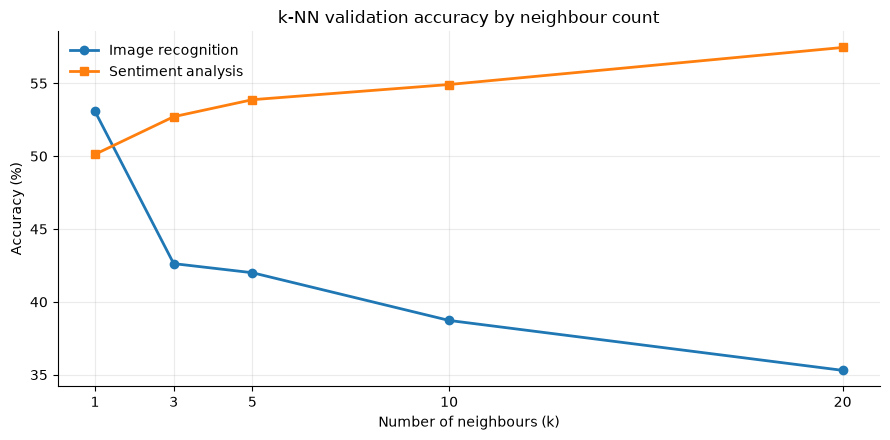

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(k_values, np.array(image_accuracies) * 100, marker="o", linewidth=2, label="Image recognition")
ax.plot(k_values, np.array(sentiment_accuracies) * 100, marker="s", linewidth=2, label="Sentiment analysis")
ax.set(title="k-NN validation accuracy by neighbour count", xlabel="Number of neighbours (k)", ylabel="Accuracy (%)")
ax.set_xticks(k_values)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("knn_accuracy_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 05 · Feature standardization

Compare Euclidean k-NN on **original** and **standardized** inputs. Scaling statistics are computed from training data only.

In [10]:
def standardize_data(X_train, X_val):
    X_train = np.asarray(X_train, dtype=np.float32)
    X_val = np.asarray(X_val, dtype=np.float32)


    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)


    std[std < 1e-8] = 1


    X_train_scaled = (X_train - mean) / std
    X_val_scaled = (X_val - mean) / std

    return X_train_scaled, X_val_scaled



X_img_train_scaled, X_img_val_scaled = standardize_data(
    X_img_train, X_img_val
)


X_sent_train_scaled, X_sent_val_scaled = standardize_data(
    X_sent_train, X_sent_val
)

print("Image scaled:", X_img_train_scaled.shape)
print("Sentiment scaled:", X_sent_train_scaled.shape)

Image scaled: (16000, 500)
Sentiment scaled: (9600, 768)


In [11]:
k_values_scaled = [1, 5, 20]
scaled_results = []

for name, X_train, X_val, y_train, y_val in [
    ("Image", X_img_train_scaled, X_img_val_scaled, y_img_train, y_img_val),
    ("Sentiment", X_sent_train_scaled, X_sent_val_scaled, y_sent_train, y_sent_val)
]:
    for k in k_values_scaled:
        model = MyKNN(k=k)
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
        accuracy = np.mean(predictions == np.asarray(y_val))
        scaled_results.append({"Task": name, "k": k, "Accuracy (%)": round(100 * accuracy, 2)})

scaled_results = pd.DataFrame(scaled_results)
display(scaled_results)

,Task,k,Accuracy (%)
0,Image,1,43.42
1,Image,5,31.72
2,Image,20,24.38
3,Sentiment,1,50.33
4,Sentiment,5,54.08
5,Sentiment,20,56.58


## 06 · Cosine distance

Test a different notion of similarity. Cosine distance compares vector direction rather than raw magnitude.

In [12]:
class CosineKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y, dtype=int)


        norms = np.linalg.norm(X, axis=1, keepdims=True)
        self.X_train = X / np.maximum(norms, 1e-8)

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)


        norms = np.linalg.norm(X, axis=1, keepdims=True)
        X = X / np.maximum(norms, 1e-8)

        predictions = []

        for start in range(0, len(X), 64):
            batch = X[start:start + 64]


            similarities = batch @ self.X_train.T

            nearest = np.argpartition(
                -similarities,
                self.k - 1,
                axis=1
            )[:, :self.k]

            for neighbors in nearest:
                labels = self.y_train[neighbors]
                prediction = np.bincount(labels).argmax()
                predictions.append(prediction)

        return np.array(predictions)

In [13]:
cosine_results = []

for name, X_train, X_val, y_train, y_val, k in [
    ("Image", X_img_train, X_img_val, y_img_train, y_img_val, 1),
    ("Sentiment", X_sent_train, X_sent_val, y_sent_train, y_sent_val, 20)
]:
    model = CosineKNN(k=k)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    accuracy = np.mean(predictions == np.asarray(y_val))
    cosine_results.append({"Task": name, "k": k, "Accuracy (%)": round(accuracy * 100, 2)})

cosine_results = pd.DataFrame(cosine_results)
display(cosine_results)

,Task,k,Accuracy (%)
0,Image,1,53.08
1,Sentiment,20,56.79


## 07 · Distance-weighted voting

Give closer neighbours more influence with weights proportional to **1 / (distance + ε)**.

In [14]:
class WeightedKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y, dtype=int)
        self.num_classes = int(self.y_train.max()) + 1


        self.train_norms = np.sum(
            self.X_train ** 2, axis=1
        )

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        predictions = []

        for start in range(0, len(X), 64):
            batch = X[start:start + 64]


            distances = (
                np.sum(batch ** 2, axis=1)[:, None]
                + self.train_norms[None, :]
                - 2 * batch @ self.X_train.T
            )

            distances = np.maximum(distances, 0)


            nearest = np.argpartition(
                distances, self.k - 1, axis=1
            )[:, :self.k]

            for i, neighbors in enumerate(nearest):
                labels = self.y_train[neighbors]


                d = np.sqrt(distances[i, neighbors])


                weights = 1 / (d + 1e-6)


                votes = np.bincount(
                    labels,
                    weights=weights,
                    minlength=self.num_classes
                )

                predictions.append(np.argmax(votes))

        return np.array(predictions)

In [15]:
weighted_results = []

for name, X_train, X_val, y_train, y_val, k in [
    ("Image", X_img_train, X_img_val, y_img_train, y_img_val, 5),
    ("Sentiment", X_sent_train, X_sent_val, y_sent_train, y_sent_val, 20)
]:
    model = WeightedKNN(k=k)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    accuracy = np.mean(predictions == np.asarray(y_val))
    weighted_results.append({"Task": name, "k": k, "Accuracy (%)": round(accuracy * 100, 2)})

weighted_results = pd.DataFrame(weighted_results)
display(weighted_results)

,Task,k,Accuracy (%)
0,Image,5,49.15
1,Sentiment,20,57.21


## 08 · Experiment summary

Use these validation results in the report. The final submission below uses the strongest **baseline Euclidean** settings tested earlier: **k = 1** for images and **k = 20** for sentiment.

In [16]:
experiment_summary = pd.concat([
    knn_results.rename(columns={"Image Accuracy (%)": "Accuracy (%)"})[["k", "Accuracy (%)"]].assign(Task="Image", Method="Euclidean · original"),
    knn_results.rename(columns={"Sentiment Accuracy (%)": "Accuracy (%)"})[["k", "Accuracy (%)"]].assign(Task="Sentiment", Method="Euclidean · original"),
    scaled_results.assign(Method="Euclidean · standardized"),
    cosine_results.assign(Method="Cosine · original"),
    weighted_results.assign(Method="Euclidean · weighted")
], ignore_index=True)[["Task", "Method", "k", "Accuracy (%)"]]

display(experiment_summary.sort_values(["Task", "Accuracy (%)"], ascending=[True, False]).reset_index(drop=True))
experiment_summary.to_csv("knn_experiments.csv", index=False)

,Task,Method,k,Accuracy (%)
0,Image,Euclidean · original,1,53.08
1,Image,Cosine · original,1,53.08
2,Image,Euclidean · weighted,5,49.15
3,Image,Euclidean · standardized,1,43.42
4,Image,Euclidean · original,3,42.62
5,Image,Euclidean · original,5,42.00
6,Image,Euclidean · original,10,38.72
7,Image,Euclidean · original,20,35.30
8,Image,Euclidean · standardized,5,31.72
9,Image,Euclidean · standardized,20,24.38


## 09 · Final Kaggle submission

Fit the chosen k-NN models using **all labeled training examples**, predict the two hidden test datasets, and match every prediction to its **ID** in the submission template.

In [17]:
image_model = MyKNN(k=1)
image_model.fit(X_image, y_image)

image_predictions = image_model.predict(
    image_test.drop(columns=["id"])
)


sentiment_model = MyKNN(k=20)
sentiment_model.fit(X_sentiment, y_sentiment)

sentiment_predictions = sentiment_model.predict(
    sentiment_test.drop(columns=["id"])
)


image_results = pd.DataFrame({
    "id": image_test["id"],
    "label": image_predictions
})

sentiment_results = pd.DataFrame({
    "id": sentiment_test["id"],
    "label": sentiment_predictions
})


all_predictions = pd.concat(
    [image_results, sentiment_results],
    ignore_index=True
)


submission = sample_submission[["id"]].merge(
    all_predictions,
    on="id",
    how="left",
    validate="one_to_one"
)


assert len(submission) == 10000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

assert submission.loc[
    submission["id"].str.startswith("img_"), "label"
].between(0, 49).all()

assert submission.loc[
    submission["id"].str.startswith("text_"), "label"
].between(0, 2).all()


submission.to_csv("submission.csv", index=False)

print("Submission created successfully!")
print(submission.shape)
display(submission.head())

Submission created successfully!
(10000, 2)


,id,label
0,text_003234,2
1,text_004517,2
2,img_000140,47
3,img_004880,15
4,text_002494,0
